In [1]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time
import torchvision.models as models
from matplotlib import pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

### Load Data

In [3]:
image_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
    ])

In [4]:
dataset_path = "./dataset"

dataset = datasets.ImageFolder(dataset_path, transform=image_transforms)
len(dataset)

2300

In [5]:
dataset[0][0]

tensor([[[-2.1179, -0.7479,  1.9407,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -0.7479,  1.9407,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -0.7479,  1.9407,  ..., -1.8953, -1.8953, -1.8953],
         ...,
         [-1.9295, -1.8953, -1.8953,  ..., -0.5767, -1.6042, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -0.5596, -1.6213, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -0.6109, -1.6384, -2.1179]],

        [[-2.0357, -0.6527,  2.0959,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -0.6527,  2.0959,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -0.6877,  2.0434,  ..., -1.8081, -1.8081, -1.7906],
         ...,
         [-1.8606, -1.8256, -1.8431,  ..., -0.5476, -1.5280, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -0.5301, -1.5630, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -0.5826, -1.5805, -2.0357]],

        [[-1.8044, -0.6018,  1.8034,  ..., -1.8044, -1.8044, -1.8044],
         [-1.8044, -0.6018,  1.7860,  ..., -1

In [56]:
class_names = dataset.classes
class_names

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [7]:
num_classes = len(dataset.classes)
num_classes

6

In [8]:
train_size = int(0.75*len(dataset))
val_size = len(dataset) - train_size

train_size, val_size

(1725, 575)

In [9]:
from torch.utils.data import random_split

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [10]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader =  DataLoader(val_dataset, batch_size=32, shuffle=True)

In [11]:
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [12]:
labels[1]

tensor(4)

In [13]:
images[1].shape

torch.Size([3, 224, 224])

In [14]:
images[1].permute(1,2,0)

tensor([[[-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         ...,
         [-1.2959, -1.2479, -1.1421],
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650]],

        [[-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         ...,
         [-1.2959, -1.2479, -1.1421],
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650]],

        [[-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         ...,
         [-1.3473, -1.2479, -1.1073],
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650]],

        ...,

        [[-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         [-1.3473, -1.2129, -1.0027],
         ...,
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650],
         [-1.9809, -1.8957, -1.6650]],

        [[

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.980906..2.4831376].


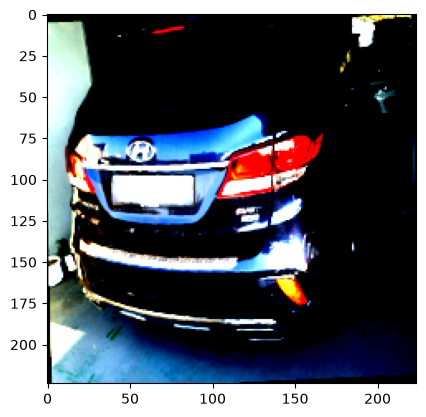

In [15]:
plt.imshow(images[1].permute(1,2,0))
plt.show()

### Model 1: CNN

In [17]:
class CarClassifierCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # in: (16, 224, 224)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (16, 112, 112)
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), 
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (32, 56, 56)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), 
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (64, 28, 28)
            nn.Flatten(),
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes)
        )
    def forward(self, x):
        x = self.network(x)
        return x     

In [18]:
# Instantiate the model, Loss function and optimizer
model = CarClassifierCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [19]:
len(train_loader.dataset)

1725

In [25]:
def train_model(model, criterion, optimizer, epochs=5):
    start = time.time()
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch_num, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass and optimization 
            loss.backward()
            optimizer.step()

            if (batch_num+1) % 10 == 0:
                print(f"Batch: {batch_num+1}, Epoch: {epoch+1}, Loss: {loss.item():0.2f}")

            running_loss += loss.item() * images.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        print(f"Epoch [{epoch+1}/{epochs}], Avg Loss: {epoch_loss:.4f}")      

        # Validation
        model.eval()
        correct = 0
        total = 0
        all_labels = []
        all_predictions = []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data,1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())
            print(f"*** Validation Accuracy: {100 * correct / total:.2f}% ***")
    
    end = time.time()
    print(f"Execution time: {end - start} seconds")      
    
    return all_labels, all_predictions

In [27]:
all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=5)

Batch: 10, Epoch: 1, Loss: 1.47
Batch: 20, Epoch: 1, Loss: 1.20
Batch: 30, Epoch: 1, Loss: 1.33
Batch: 40, Epoch: 1, Loss: 1.31
Batch: 50, Epoch: 1, Loss: 1.25
Epoch [1/5], Avg Loss: 1.3413
*** Validation Accuracy: 48.35% ***
Batch: 10, Epoch: 2, Loss: 1.28
Batch: 20, Epoch: 2, Loss: 1.38
Batch: 30, Epoch: 2, Loss: 1.17
Batch: 40, Epoch: 2, Loss: 1.36
Batch: 50, Epoch: 2, Loss: 1.48
Epoch [2/5], Avg Loss: 1.1552
*** Validation Accuracy: 54.78% ***
Batch: 10, Epoch: 3, Loss: 1.53
Batch: 20, Epoch: 3, Loss: 1.02
Batch: 30, Epoch: 3, Loss: 0.92
Batch: 40, Epoch: 3, Loss: 0.86
Batch: 50, Epoch: 3, Loss: 0.71
Epoch [3/5], Avg Loss: 1.0292
*** Validation Accuracy: 53.39% ***
Batch: 10, Epoch: 4, Loss: 1.05
Batch: 20, Epoch: 4, Loss: 0.84
Batch: 30, Epoch: 4, Loss: 0.94
Batch: 40, Epoch: 4, Loss: 0.88
Batch: 50, Epoch: 4, Loss: 0.93
Epoch [4/5], Avg Loss: 0.9488
*** Validation Accuracy: 57.57% ***
Batch: 10, Epoch: 5, Loss: 0.66
Batch: 20, Epoch: 5, Loss: 0.67
Batch: 30, Epoch: 5, Loss: 0.86


### Model 2: CNN with Regularization

In [28]:
class CarClassifierCNNWithRegularization(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # in: (16, 224, 224)
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (16, 112, 112)
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (32, 56, 56)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (64, 28, 28)
            nn.Flatten(),
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    def forward(self, x):
        x = self.network(x)
        return x     

In [29]:
model = CarClassifierCNNWithRegularization(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

all_labels, all_predictions = train_model(model, criterion, optimizer,  epochs=5)

Batch: 10, Epoch: 1, Loss: 26.25
Batch: 20, Epoch: 1, Loss: 9.05
Batch: 30, Epoch: 1, Loss: 4.42
Batch: 40, Epoch: 1, Loss: 1.71
Batch: 50, Epoch: 1, Loss: 1.66
Epoch [1/5], Avg Loss: 8.9876
*** Validation Accuracy: 39.30% ***
Batch: 10, Epoch: 2, Loss: 1.52
Batch: 20, Epoch: 2, Loss: 1.59
Batch: 30, Epoch: 2, Loss: 1.27
Batch: 40, Epoch: 2, Loss: 1.31
Batch: 50, Epoch: 2, Loss: 1.37
Epoch [2/5], Avg Loss: 1.5059
*** Validation Accuracy: 48.35% ***
Batch: 10, Epoch: 3, Loss: 1.50
Batch: 20, Epoch: 3, Loss: 1.13
Batch: 30, Epoch: 3, Loss: 1.49
Batch: 40, Epoch: 3, Loss: 1.25
Batch: 50, Epoch: 3, Loss: 1.34
Epoch [3/5], Avg Loss: 1.3814
*** Validation Accuracy: 48.87% ***
Batch: 10, Epoch: 4, Loss: 1.19
Batch: 20, Epoch: 4, Loss: 1.32
Batch: 30, Epoch: 4, Loss: 1.33
Batch: 40, Epoch: 4, Loss: 1.25
Batch: 50, Epoch: 4, Loss: 1.21
Epoch [4/5], Avg Loss: 1.2966
*** Validation Accuracy: 47.65% ***
Batch: 10, Epoch: 5, Loss: 1.19
Batch: 20, Epoch: 5, Loss: 1.37
Batch: 30, Epoch: 5, Loss: 1.11

### Model 3: Transfer Learning with EfficientNet

In [31]:
model = models.efficientnet_b0(weights='DEFAULT')
model.classifier[1].in_features

1280

In [32]:
class CarClassifierEfficientNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.efficientnet_b0(weights='DEFAULT')

        for param in self.model.parameters():
            param.requires_grad = False
        
        in_features = self.model.classifier[1].in_features
        
        self.model.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

In [33]:
model = CarClassifierEfficientNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.65
Batch: 20, Epoch: 1, Loss: 1.55
Batch: 30, Epoch: 1, Loss: 1.43
Batch: 40, Epoch: 1, Loss: 1.55
Batch: 50, Epoch: 1, Loss: 1.28
Epoch [1/10], Avg Loss: 1.4769
*** Validation Accuracy: 58.09% ***
Batch: 10, Epoch: 2, Loss: 1.18
Batch: 20, Epoch: 2, Loss: 1.05
Batch: 30, Epoch: 2, Loss: 1.16
Batch: 40, Epoch: 2, Loss: 1.29
Batch: 50, Epoch: 2, Loss: 0.96
Epoch [2/10], Avg Loss: 1.1298
*** Validation Accuracy: 61.22% ***
Batch: 10, Epoch: 3, Loss: 1.09
Batch: 20, Epoch: 3, Loss: 1.11
Batch: 30, Epoch: 3, Loss: 0.92
Batch: 40, Epoch: 3, Loss: 1.07
Batch: 50, Epoch: 3, Loss: 1.18
Epoch [3/10], Avg Loss: 1.0230
*** Validation Accuracy: 64.70% ***
Batch: 10, Epoch: 4, Loss: 1.05
Batch: 20, Epoch: 4, Loss: 0.93
Batch: 30, Epoch: 4, Loss: 0.97
Batch: 40, Epoch: 4, Loss: 0.88
Batch: 50, Epoch: 4, Loss: 0.83
Epoch [4/10], Avg Loss: 0.9356
*** Validation Accuracy: 64.35% ***
Batch: 10, Epoch: 5, Loss: 0.91
Batch: 20, Epoch: 5, Loss: 1.02
Batch: 30, Epoch: 5, Loss: 0

### Model 4: Transfer Learning with ResNet

In [34]:
# Load the pre-trained ResNet model
class CarClassifierResNet(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5):
        super().__init__()
        self.model = models.resnet50(weights='DEFAULT')
        # Freeze all layers except the final fully connected layer
        for param in self.model.parameters():
            param.requires_grad = False
            
        # Unfreeze layer4 and fc layers
        for param in self.model.layer4.parameters():
            param.requires_grad = True            
            
        # Replace the final fully connected layer
        self.model.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(self.model.fc.in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

In [35]:
model = CarClassifierResNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

labels, predictions = train_model(model, criterion, optimizer, epochs=10)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\saul_/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:17<00:00, 5.98MB/s]


Batch: 10, Epoch: 1, Loss: 1.09
Batch: 20, Epoch: 1, Loss: 1.03
Batch: 30, Epoch: 1, Loss: 0.58
Batch: 40, Epoch: 1, Loss: 0.58
Batch: 50, Epoch: 1, Loss: 0.73
Epoch [1/10], Avg Loss: 0.9006
*** Validation Accuracy: 70.96% ***
Batch: 10, Epoch: 2, Loss: 0.69
Batch: 20, Epoch: 2, Loss: 0.50
Batch: 30, Epoch: 2, Loss: 0.63
Batch: 40, Epoch: 2, Loss: 0.66
Batch: 50, Epoch: 2, Loss: 0.41
Epoch [2/10], Avg Loss: 0.4915
*** Validation Accuracy: 77.39% ***
Batch: 10, Epoch: 3, Loss: 0.22
Batch: 20, Epoch: 3, Loss: 0.32
Batch: 30, Epoch: 3, Loss: 0.33
Batch: 40, Epoch: 3, Loss: 0.54
Batch: 50, Epoch: 3, Loss: 0.33
Epoch [3/10], Avg Loss: 0.3457
*** Validation Accuracy: 80.00% ***
Batch: 10, Epoch: 4, Loss: 0.38
Batch: 20, Epoch: 4, Loss: 0.38
Batch: 30, Epoch: 4, Loss: 0.20
Batch: 40, Epoch: 4, Loss: 0.10
Batch: 50, Epoch: 4, Loss: 0.40
Epoch [4/10], Avg Loss: 0.2440
*** Validation Accuracy: 77.74% ***
Batch: 10, Epoch: 5, Loss: 0.14
Batch: 20, Epoch: 5, Loss: 0.45
Batch: 30, Epoch: 5, Loss: 0

### I ran hyperparameter tunning in another notebook and figured that the best parameters for resnet models are (1) Dropout rate = 0.2 (2) Learning Rate = 0.005
So now let's train the model once again with these best parameters

In [49]:
model = CarClassifierResNet(num_classes=num_classes, dropout_rate=0.2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.005)

labels, predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 0.92
Batch: 20, Epoch: 1, Loss: 0.72
Batch: 30, Epoch: 1, Loss: 0.59
Batch: 40, Epoch: 1, Loss: 0.63
Batch: 50, Epoch: 1, Loss: 0.62
Epoch [1/10], Avg Loss: 0.8477
*** Validation Accuracy: 71.13% ***
Batch: 10, Epoch: 2, Loss: 0.39
Batch: 20, Epoch: 2, Loss: 0.39
Batch: 30, Epoch: 2, Loss: 0.78
Batch: 40, Epoch: 2, Loss: 0.59
Batch: 50, Epoch: 2, Loss: 0.66
Epoch [2/10], Avg Loss: 0.5402
*** Validation Accuracy: 73.57% ***
Batch: 10, Epoch: 3, Loss: 0.41
Batch: 20, Epoch: 3, Loss: 0.22
Batch: 30, Epoch: 3, Loss: 0.31
Batch: 40, Epoch: 3, Loss: 0.30
Batch: 50, Epoch: 3, Loss: 0.27
Epoch [3/10], Avg Loss: 0.3621
*** Validation Accuracy: 83.48% ***
Batch: 10, Epoch: 4, Loss: 0.19
Batch: 20, Epoch: 4, Loss: 0.30
Batch: 30, Epoch: 4, Loss: 0.15
Batch: 40, Epoch: 4, Loss: 0.23
Batch: 50, Epoch: 4, Loss: 0.35
Epoch [4/10], Avg Loss: 0.3220
*** Validation Accuracy: 81.04% ***
Batch: 10, Epoch: 5, Loss: 0.14
Batch: 20, Epoch: 5, Loss: 0.44
Batch: 30, Epoch: 5, Loss: 0

### Model Evaluation using Confusion Matrix and Classification Report

In [54]:
from sklearn.metrics import classification_report

report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.81      0.88      0.85       113
           1       0.81      0.73      0.77       113
           2       0.91      0.88      0.89       129
           3       0.90      0.76      0.83        72
           4       0.65      0.83      0.73        66
           5       0.82      0.80      0.81        82

    accuracy                           0.82       575
   macro avg       0.82      0.82      0.81       575
weighted avg       0.83      0.82      0.82       575



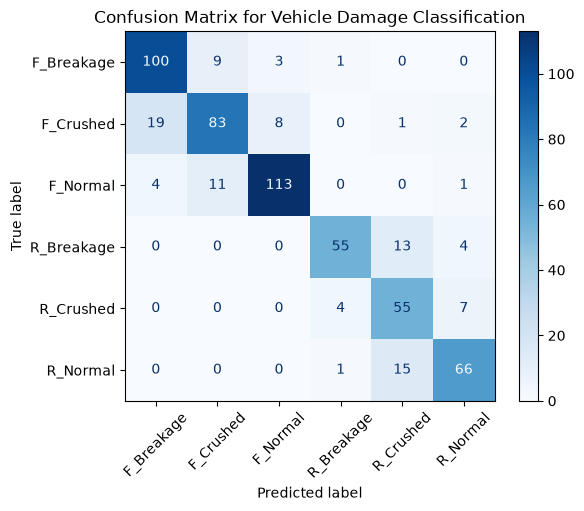

In [57]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

conf_matrix = confusion_matrix(labels, predictions, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix for Vehicle Damage Classification")
plt.show()

In [58]:
torch.save(model.state_dict(), 'save_model.pth')